# IMDB Sentiment Classification (TP6 Series)

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 1 SIEC · 2023–2024 (inferred from neighboring numbered TP series; not explicitly in this source file)  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify movie review sentiment using text-sequence models.

**Approach:** TensorFlow/Keras IMDB review sequences.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, GRU, Dense
import matplotlib.pyplot as plt


In [ ]:
# Step 1: Load the IMDb movie reviews dataset
def load_data(num_words, maxlen):
    (X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

    # Pad sequences to ensure uniform length
    X_train = pad_sequences(X_train, maxlen=maxlen)
    X_test = pad_sequences(X_test, maxlen=maxlen)

    return (X_train, y_train), (X_test, y_test)

In [ ]:

# Step 4: Build RNN, LSTM, and GRU models
def build_rnn_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        tf.keras.layers.SimpleRNN(128),
        Dense(1, activation='sigmoid')
    ])
    return model

In [ ]:
def build_lstm_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        LSTM(128),
        Dense(1, activation='sigmoid')
    ])
    return model


In [ ]:
def build_gru_model(num_words, embedding_dim, maxlen):
    model = Sequential([
        Embedding(num_words, embedding_dim),
        GRU(128),
        Dense(1, activation='sigmoid')
    ])
    return model


In [ ]:
# Step 6: Evaluate and compare the models
def evaluate_model(model, X_test, y_test):
    loss, accuracy = model.evaluate(X_test, y_test)
    return loss, accuracy


In [ ]:

# Step 7: Visualize and analyze results
def plot_history(history):
    plt.plot(history.history['accuracy'], label='accuracy')
    plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.show()


In [ ]:
def train_model(model, X_train, y_train, X_val, y_val, batch_size, epochs):
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    history = model.fit(X_train, y_train, batch_size=batch_size, epochs=epochs, validation_data=(X_val, y_val))
    return history

Epoch 1/5
352/352 [==============================] - 19s 50ms/step - loss: 0.6526 - accuracy: 0.5906 - val_loss: 0.6526 - val_accuracy: 0.6212
Epoch 2/5
352/352 [==============================] - 18s 50ms/step - loss: 0.5325 - accuracy: 0.7320 - val_loss: 0.5936 - val_accuracy: 0.6656
Epoch 3/5
352/352 [==============================] - 18s 51ms/step - loss: 0.4516 - accuracy: 0.7904 - val_loss: 0.4621 - val_accuracy: 0.7848
Epoch 4/5
352/352 [==============================] - 18s 51ms/step - loss: 0.3758 - accuracy: 0.8377 - val_loss: 0.4845 - val_accuracy: 0.7752
Epoch 5/5
352/352 [==============================] - 17s 50ms/step - loss: 0.3763 - accuracy: 0.8394 - val_loss: 0.4961 - val_accuracy: 0.7680
Epoch 1/5
352/352 [==============================] - 72s 199ms/step - loss: 0.4359 - accuracy: 0.7935 - val_loss: 0.3405 - val_accuracy: 0.8580
Epoch 2/5
352/352 [==============================] - 76s 215ms/step - loss: 0.2471 - accuracy: 0.9048 - val_loss: 0.3025 - val_accuracy: 0.87

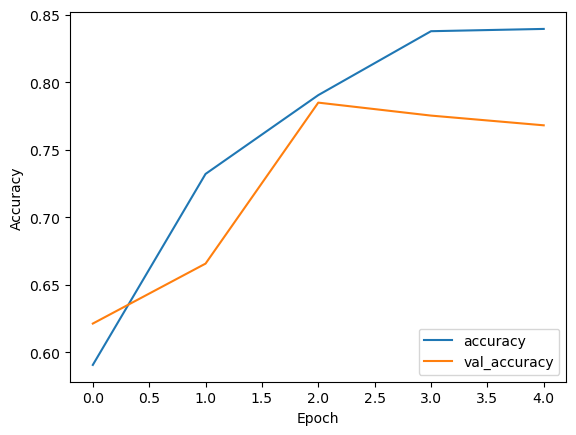

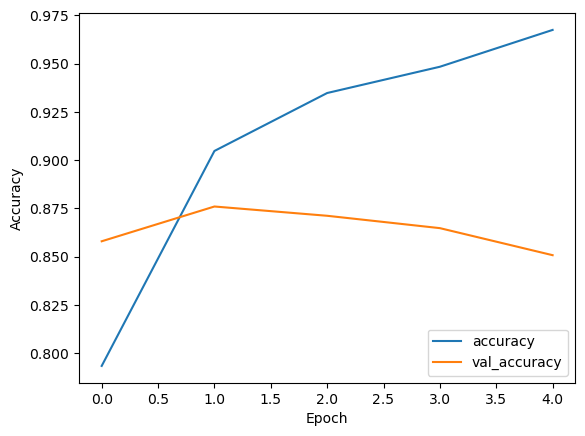

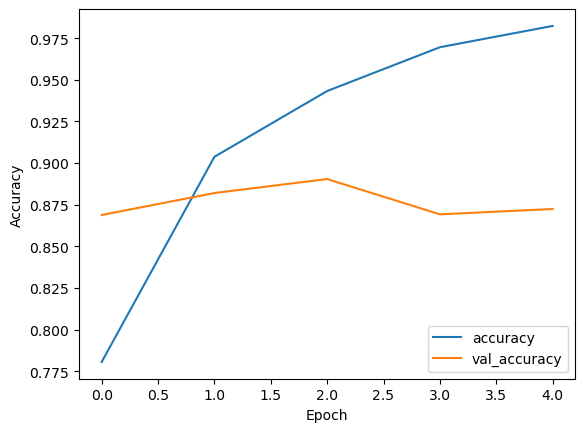

In [ ]:
# Main function to run the entire pipeline
def main():
    # Hyperparameters
    num_words = 10000  # Number of words to keep from the dataset
    maxlen = 200  # Maximum length of sequences
    embedding_dim = 128
    batch_size = 64
    epochs = 5

    # Step 1: Load the data
    (X_train, y_train), (X_test, y_test) = load_data(num_words, maxlen)

    # Step 3: Split the data into training, validation, and test sets
    validation_split = 0.1
    validation_samples = int(len(X_train) * validation_split)
    X_val = X_train[:validation_samples]
    y_val = y_train[:validation_samples]
    X_train = X_train[validation_samples:]
    y_train = y_train[validation_samples:]

    # Step 4: Build the models
    rnn_model = build_rnn_model(num_words, embedding_dim, maxlen)
    lstm_model = build_lstm_model(num_words, embedding_dim, maxlen)
    gru_model = build_gru_model(num_words, embedding_dim, maxlen)

    # Step 5: Train and optimize the models
    rnn_history = train_model(rnn_model, X_train, y_train, X_val, y_val, batch_size, epochs)
    lstm_history = train_model(lstm_model, X_train, y_train, X_val, y_val, batch_size, epochs)
    gru_history = train_model(gru_model, X_train, y_train, X_val, y_val, batch_size, epochs)

    # Step 6: Evaluate and compare the models
    rnn_loss, rnn_accuracy = evaluate_model(rnn_model, X_test, y_test)
    lstm_loss, lstm_accuracy = evaluate_model(lstm_model, X_test, y_test)
    gru_loss, gru_accuracy = evaluate_model(gru_model, X_test, y_test)

    print("RNN Test Accuracy:", rnn_accuracy)
    print("LSTM Test Accuracy:", lstm_accuracy)
    print("GRU Test Accuracy:", gru_accuracy)

    # Step 7: Visualize and analyze results
    plot_history(rnn_history)
    plot_history(lstm_history)
    plot_history(gru_history)

if __name__ == "__main__":
    main()

